# Product Catalog Data Quality Audit — Part 2: SQL Analysis

**Author:** RoShawn Frazier

Part 1 cleaned the raw data and built a product master. Here I load both tables into a SQL database and answer the questions a catalog manager would ask: how healthy is the catalog, where should cleanup start, which prices look wrong, and which products drive sales.

**Tables**
- `products`: one row per product (4,723 rows), from `outputs/product_master.csv`
- `transactions`: one row per clean sales line (about 1 million rows), from `outputs/clean_transactions.csv.gz`

All queries are also saved in `queries.sql`. Prices and revenue are in British pounds.

## Load the data into SQLite
SQLite is a database built into Python, so this runs anywhere, including Google Colab, with no setup.

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

transactions = pd.read_csv('outputs/clean_transactions.csv.gz', dtype={'Invoice': str, 'StockCode': str})
products = pd.read_csv('outputs/product_master.csv', dtype={'StockCode': str})
products['needs_review'] = products['needs_review'].astype(int)

con = sqlite3.connect(':memory:')
transactions.to_sql('transactions', con, index=False)
products.to_sql('products', con, index=False)
con.execute('CREATE INDEX ix_transactions_code ON transactions(StockCode)')

def q(sql):
    return pd.read_sql(sql, con)

print(f'transactions: {len(transactions):,} rows | products: {len(products):,} rows')

transactions: 1,003,338 rows | products: 4,723 rows


## Q1. Catalog health overview
Start with the big picture: how much of the catalog has inconsistent product names?

In [2]:
q("""
-- Q1. Catalog health overview: how many products need a description review?
SELECT COUNT(*)                                           AS total_products,
       SUM(needs_review)                                  AS needs_review,
       ROUND(100.0 * SUM(needs_review) / COUNT(*), 1)     AS pct_needs_review,
       MAX(description_variants)                          AS most_names_for_one_product
FROM products;
""")

,total_products,needs_review,pct_needs_review,most_names_for_one_product
0,4723,595,12.6,4


**Finding:** 595 of 4,723 products (12.6%) were sold under more than one name, and some had as many as four.

## Q2. Where to start the cleanup
Products with the most conflicting names, sorted so the busiest products come first. Fixing these gives the biggest improvement for the effort.

In [3]:
q("""
-- Q2. Products with the most conflicting names: where to start the cleanup
SELECT StockCode, canonical_description, description_variants, invoice_lines
FROM products
WHERE needs_review = 1
ORDER BY description_variants DESC, invoice_lines DESC
LIMIT 10;
""")

,StockCode,canonical_description,description_variants,invoice_lines
0,22384,LUNCH BAG PINK POLKADOT,4,2137
1,20685,DOORMAT RED RETROSPOT,4,1728
2,23236,STORAGE TIN VINTAGE DOILY,4,330
3,23196,VINTAGE LEAF MAGNETIC NOTEPAD,4,304
4,22344,PARTY PIZZA DISH PINK POLKADOT,4,133
5,22345,PARTY PIZZA DISH BLUE POLKADOT,4,130
6,22346,PARTY PIZZA DISH GREEN POLKADOT,4,104
7,85099B,JUMBO BAG RED RETROSPOT,3,4067
8,22197,SMALL POPCORN HOLDER,3,2366
9,22139,RETROSPOT TEA SET CERAMIC 11 PC,3,2103


**Finding:** high-volume items like `LUNCH BAG PINK POLKADOT` (2,137 sales lines) and `JUMBO BAG RED RETROSPOT` (4,067 lines) have multiple names. These are the first records to fix.

## Q3. Why the cleanup matters
How much revenue comes from products whose names conflict? This turns a data quality issue into a business number.

In [4]:
q("""
-- Q3. Revenue tied to products with conflicting names: why the cleanup matters
SELECT p.needs_review,
       COUNT(DISTINCT p.StockCode)                                   AS products,
       ROUND(SUM(t.Revenue), 0)                                      AS revenue,
       ROUND(100.0 * SUM(t.Revenue) / (SELECT SUM(Revenue) FROM transactions), 1) AS pct_of_revenue
FROM transactions t
JOIN products p ON p.StockCode = t.StockCode
GROUP BY p.needs_review;
""")

,needs_review,products,revenue,pct_of_revenue
0,0,4128,14509153.0,73.9
1,1,595,5134694.0,26.1


**Finding:** the 595 products with conflicting names account for about 26% of revenue, roughly £5.1 million. Inconsistent names on these products affect search results and split their sales across several names in reports.

## Q4. Top products by revenue
The products that matter most. Their catalog records should be the most accurate.

In [5]:
q("""
-- Q4. Top 10 products by revenue
SELECT p.StockCode, p.canonical_description,
       SUM(t.Quantity)            AS units_sold,
       ROUND(SUM(t.Revenue), 0)   AS revenue
FROM transactions t
JOIN products p ON p.StockCode = t.StockCode
GROUP BY p.StockCode, p.canonical_description
ORDER BY revenue DESC
LIMIT 10;
""")

,StockCode,canonical_description,units_sold,revenue
0,22423,REGENCY CAKESTAND 3 TIER,26478,330590.0
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94719,261169.0
2,85099B,JUMBO BAG RED RETROSPOT,97176,182681.0
3,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168470.0
4,47566,PARTY BUNTING,28200,148318.0
5,84879,ASSORTED COLOUR BIRD ORNAMENT,80082,129324.0
6,22086,PAPER CHAIN KIT 50'S CHRISTMAS,35084,117760.0
7,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81701.0
8,79321,CHILLI LIGHTS,15841,80541.0
9,22197,SMALL POPCORN HOLDER,88499,79520.0


**Finding:** `REGENCY CAKESTAND 3 TIER` is the top product by revenue, at about £331,000.

## Q5. Pricing consistency check
Prices naturally vary with bulk discounts, but a highest price 5x or more above the lowest is worth checking for entry errors.

In [6]:
q("""
-- Q5. Pricing consistency: products whose highest price is 5x+ their lowest.
-- Some spread is normal (bulk discounts), but large gaps are worth checking for entry errors.
SELECT StockCode, canonical_description, min_price, median_price, max_price,
       ROUND(max_price / min_price, 1) AS price_ratio, invoice_lines
FROM products
WHERE max_price / min_price >= 5 AND invoice_lines >= 50
ORDER BY price_ratio DESC
LIMIT 10;
""")

,StockCode,canonical_description,min_price,median_price,max_price,price_ratio,invoice_lines
0,84016,FLAG OF ST GEORGE CAR FLAG,0.35,0.42,1157.15,3306.1,62
1,22502,PICNIC BASKET WICKER SMALL,2.00,5.95,649.50,324.8,931
2,84879,ASSORTED COLOUR BIRD ORNAMENT,0.14,1.69,26.04,186.0,2848
3,22499,WOODEN UNION JACK BUNTING,0.10,5.95,13.57,135.7,778
4,21135,VICTORIAN METAL POSTCARD SPRING,0.20,1.69,25.49,127.4,416
5,37340,MULTICOLOUR SPRING FLOWER MUG,0.10,0.85,8.65,86.5,205
6,79164,BLACK WINE GLASS,0.39,1.65,21.70,55.6,92
7,79163,BLACK CHAMPAGNE GLASS,0.39,1.45,21.23,54.4,65
8,84033,FLAG OF ST GEORGE,1.65,1.65,85.10,51.6,50
9,85175,CACTI T-LIGHT CANDLES,0.27,0.42,13.87,51.4,444


**Finding:** a car flag with a median price of £0.42 was recorded at £1,157.15, which looks like an entry error. A small wicker picnic basket priced at £649.50 turned out to be a separate 60-piece bulk lot sold under the same product code. Both are the kind of record a catalog review should catch.

## Q6. Inactive products
Products with no sales in the last six months of the data are candidates to retire or review, which keeps the catalog lean.

In [7]:
q("""
-- Q6. Inactive products: no sales in the last 6 months of data (candidates to retire from the catalog)
SELECT COUNT(*) AS inactive_products,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM products), 1) AS pct_of_catalog
FROM products
WHERE last_sold < DATE((SELECT MAX(InvoiceDate) FROM transactions), '-6 months');
""")

,inactive_products,pct_of_catalog
0,1352,28.6


**Finding:** 1,352 products (28.6% of the catalog) had no sales in the final six months, a large group to review for retirement.

## Q7. Monthly revenue trend
Uses a window function (`LAG`) to compare each month with the one before. December 2011 is excluded because the data stops on December 9.

In [8]:
q("""
-- Q7. Monthly revenue with month-over-month change (window function).
-- December 2011 is excluded because the data ends on Dec 9.
WITH monthly AS (
    SELECT STRFTIME('%Y-%m', InvoiceDate) AS month,
           ROUND(SUM(Revenue), 0)         AS revenue
    FROM transactions
    WHERE InvoiceDate < '2011-12-01'
    GROUP BY month
)
SELECT month, revenue,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY month))
             / LAG(revenue) OVER (ORDER BY month), 1) AS pct_change
FROM monthly
ORDER BY month;
""")

,month,revenue,pct_change
0,2009-12,797901.0,NaN
1,2010-01,612297.0,-23.3
2,2010-02,537910.0,-12.1
3,2010-03,761706.0,41.6
4,2010-04,646341.0,-15.1
5,2010-05,643492.0,-0.4
6,2010-06,696583.0,8.3
7,2010-07,632994.0,-9.1
8,2010-08,674038.0,6.5
9,2010-09,869243.0,29.0


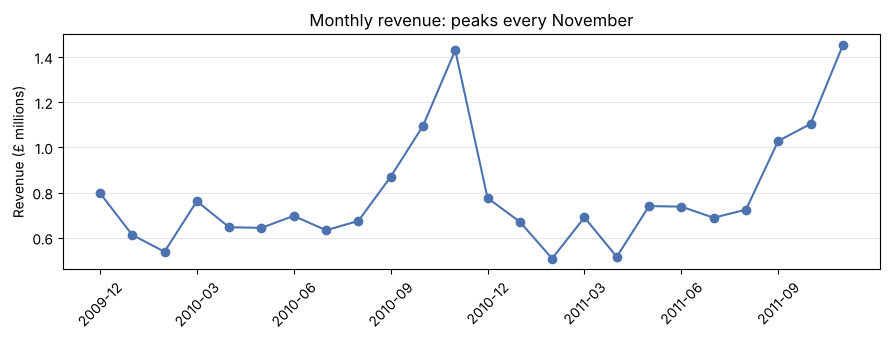

In [9]:
monthly = q('''
SELECT STRFTIME('%Y-%m', InvoiceDate) AS month, SUM(Revenue) AS revenue
FROM transactions WHERE InvoiceDate < '2011-12-01'
GROUP BY month ORDER BY month''')
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(monthly['month'], monthly['revenue'] / 1e6, marker='o', color='#4C72B0')
ax.set_ylabel('Revenue (£ millions)')
ax.set_title('Monthly revenue: peaks every November')
ax.set_xticks(range(0, len(monthly), 3))
ax.set_xticklabels(monthly['month'][::3], rotation=45)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('outputs/monthly_revenue.png', dpi=150)
plt.show()

**Finding:** sales are strongly seasonal. Revenue climbs from September and peaks in November both years at about £1.4 million, then drops sharply in December and January. Catalog updates for holiday products should be finished before September.

## Q8. Revenue by country
Where sales come from.

In [10]:
q("""
-- Q8. Revenue by country (top 10), with each country's share
SELECT Country,
       COUNT(DISTINCT Invoice)    AS orders,
       ROUND(SUM(Revenue), 0)     AS revenue,
       ROUND(100.0 * SUM(Revenue) / (SELECT SUM(Revenue) FROM transactions), 1) AS pct_of_revenue
FROM transactions
GROUP BY Country
ORDER BY revenue DESC
LIMIT 10;
""")

,Country,orders,revenue,pct_of_revenue
0,United Kingdom,36184,16801005.0,85.5
1,EIRE,581,623414.0,3.2
2,Netherlands,216,549773.0,2.8
3,Germany,753,383289.0,2.0
4,France,598,311090.0,1.6
5,Australia,89,167800.0,0.9
6,Spain,144,97767.0,0.5
7,Switzerland,85,94025.0,0.5
8,Sweden,99,86319.0,0.4
9,Denmark,42,67423.0,0.3


**Finding:** the United Kingdom accounts for 85.5% of revenue. Ireland (EIRE), the Netherlands and Germany are the largest international markets.

## Q9. Best seller in each top country
Uses `RANK()` with `PARTITION BY` to find the number-one product in each of the top five countries.

In [11]:
q("""
-- Q9. Best-selling product in each of the top 5 countries (window function: RANK)
WITH country_product AS (
    SELECT t.Country, p.canonical_description,
           SUM(t.Revenue) AS revenue,
           RANK() OVER (PARTITION BY t.Country ORDER BY SUM(t.Revenue) DESC) AS rnk
    FROM transactions t
    JOIN products p ON p.StockCode = t.StockCode
    GROUP BY t.Country, p.StockCode
),
top_countries AS (
    SELECT Country FROM transactions GROUP BY Country ORDER BY SUM(Revenue) DESC LIMIT 5
)
SELECT cp.Country, cp.canonical_description AS top_product, ROUND(cp.revenue, 0) AS revenue
FROM country_product cp
JOIN top_countries tc ON tc.Country = cp.Country
WHERE cp.rnk = 1
ORDER BY cp.revenue DESC;
""")

,Country,top_product,revenue
0,United Kingdom,REGENCY CAKESTAND 3 TIER,277783.0
1,EIRE,REGENCY CAKESTAND 3 TIER,15497.0
2,Germany,REGENCY CAKESTAND 3 TIER,13549.0
3,Netherlands,ROUND SNACK BOXES SET OF4 WOODLAND,13315.0
4,France,RABBIT NIGHT LIGHT,7277.0


**Finding:** the cake stand leads in the UK, Ireland and Germany, while the Netherlands and France have different best sellers.

## Summary
- **Catalog health:** 12.6% of products have conflicting names, and they carry about a quarter of revenue. Fixing the busiest ones first gives the most improvement for the effort.
- **Pricing:** a handful of products show extreme price swings. The worst look like entry errors or bulk lots sharing a product code, and they should be reviewed.
- **Catalog size:** about 29% of products had no recent sales and could be retired or reviewed.
- **Timing:** sales peak every November, so catalog updates for seasonal products should be done by early fall.

**Next:** Part 3, a dashboard of catalog health and sales trends.